### **Image Histogram and Equalization**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Computer_Vision_In_Python/blob/main/Algorithms/Image_Histogram.ipynb)

> An **image histogram** counts how many pixels have each gray level (0 to 255). It shows at a glance whether an image is dark, bright, or low in contrast. This notebook computes the absolute and relative histograms, the cumulative distribution, and improves contrast with **global histogram equalization** and **CLAHE**.

In [1]:
# Import libraries and helpers (images load from ../Images locally, or from GitHub in Colab)
import os
import urllib.request

import cv2
import numpy as np
from matplotlib import pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/jrafa1607/Computer_Vision_In_Python/main/Images/"

def load_image(name, flags=cv2.IMREAD_COLOR):
    """Returns the image in OpenCV format (BGR for color images)."""
    local = os.path.join("..", "Images", name)
    if os.path.exists(local):
        data = np.fromfile(local, np.uint8)
    else:
        with urllib.request.urlopen(BASE_URL + name) as response:
            data = np.frombuffer(response.read(), np.uint8)
    return cv2.imdecode(data, flags)

def show(images, titles, size=(14, 4)):
    """Shows images side by side; color images are converted from BGR to RGB for Matplotlib."""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [2]:
# Load the image and convert it to grayscale
gray = cv2.cvtColor(load_image("astronaut.png"), cv2.COLOR_BGR2GRAY)
print("Pixels:", gray.size)

Pixels: 262144


#### **01. Absolute and Relative Histograms**

The **relative histogram** divides each count by the number of pixels, giving the probability of each gray level (the values add up to 1). The **cumulative distribution (CDF)** is the running sum of that probability.

Sum of the relative histogram: 1.000 | Mean gray level: 115.4


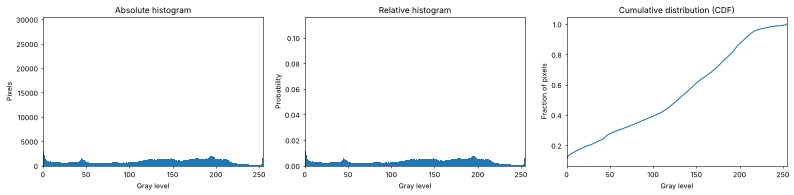

In [3]:
# Absolute histogram, relative histogram, and cumulative distribution
hist = np.bincount(gray.ravel(), minlength=256)
relative = hist / gray.size
cdf = np.cumsum(relative)
print(f"Sum of the relative histogram: {relative.sum():.3f} | Mean gray level: {gray.mean():.1f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(range(256), hist, width=1); axes[0].set_title("Absolute histogram"); axes[0].set_ylabel("Pixels")
axes[1].bar(range(256), relative, width=1); axes[1].set_title("Relative histogram"); axes[1].set_ylabel("Probability")
axes[2].plot(cdf); axes[2].set_title("Cumulative distribution (CDF)"); axes[2].set_ylabel("Fraction of pixels")
for ax in axes: ax.set_xlabel("Gray level"); ax.set_xlim(0, 255)
plt.tight_layout(); plt.show()

#### **02. Histogram Equalization and CLAHE**

* **Global equalization** maps each gray level through the CDF, spreading the values over the full range. It can over-amplify noise and wash out regions that were already well exposed.
* **CLAHE** (Contrast Limited Adaptive Histogram Equalization) equalizes small tiles separately and clips the histogram to limit noise amplification.

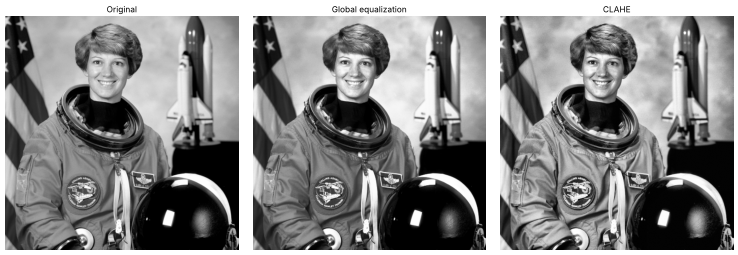

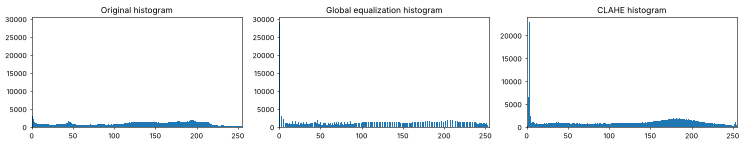

In [4]:
# Global equalization and CLAHE
equalized = cv2.equalizeHist(gray)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
show([gray, equalized, clahe], ["Original", "Global equalization", "CLAHE"], size=(15, 5))

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, image, title in zip(axes, [gray, equalized, clahe], ["Original", "Global equalization", "CLAHE"]):
    ax.bar(range(256), np.bincount(image.ravel(), minlength=256), width=1)
    ax.set_title(f"{title} histogram"); ax.set_xlim(0, 255)
plt.tight_layout(); plt.show()

#### **Key Takeaways**

* A relative histogram is a probability distribution: plot it against the gray levels, not as a histogram of its own values.
* Global equalization flattens the histogram; CLAHE improves local contrast with fewer artifacts and is usually preferred for real images.